# Practical 4 – Tackle Noise with Error Correction

**Problem Statement:** Tackle noise with error correction.

**Objective:** Understand how to tackle noise with quantum error correction.

**Outcome:** Displays the circuit for tackling noise with error correction.

**Theory:** Real qubits are affected by **noise** (decoherence, gate errors) which can flip a qubit (bit-flip, X error)
or its phase (phase-flip, Z error). Quantum states cannot be copied, so instead we **encode** one *logical* qubit in
several *physical* qubits using entanglement:

* **3-qubit bit-flip code:** α|0⟩+β|1⟩ → α|000⟩+β|111⟩ (two CNOTs).
* Two **ancilla** qubits measure the parities q0⊕q1 and q1⊕q2 (the *syndrome*) without disturbing the logical state.
* The syndrome tells which qubit flipped and we correct it with an X gate:

| Syndrome (s1 s0) | Error on | Correction |
|---|---|---|
| 00 | none | – |
| 01 | q0 | X on q0 |
| 11 | q1 | X on q1 |
| 10 | q2 | X on q2 |

* The **phase-flip code** is the same circuit surrounded by Hadamard gates (Z errors become X errors in the |+⟩/|−⟩ basis).

A single error is always corrected, so the logical error rate drops from *p* to about *3p²*.

In [1]:
# Run this cell first in Google Colab (installs Qiskit + simulator)
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jadha\AppData\Local\Temp\claude\efb368ed25e968d0\a89940ab-0696-4fca-91e1-025ecd80d2c1\scratchpad\qenv\Scripts\python.exe -m pip install --upgrade pip


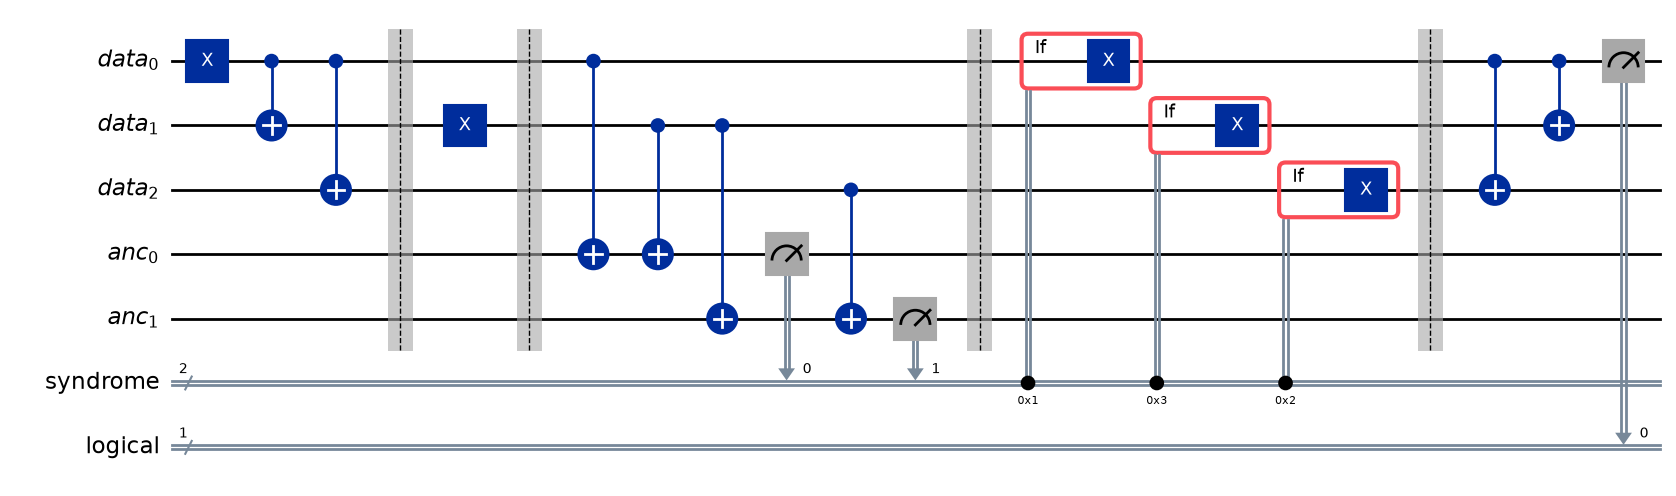

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

def bit_flip_code(error_qubit=None, phase=False, noisy_id=False):
    """3-qubit repetition code with syndrome measurement and correction.
    error_qubit: inject an X (or Z if phase=True) error on this data qubit.
    noisy_id:    put an 'id' gate on each data qubit where the noise model acts."""
    data = QuantumRegister(3, "data")
    anc = QuantumRegister(2, "anc")
    syn = ClassicalRegister(2, "syndrome")
    out = ClassicalRegister(1, "logical")
    qc = QuantumCircuit(data, anc, syn, out)

    # Logical state to protect: |1>  (|+> -> measured in X basis for phase code)
    qc.x(data[0])
    # Encode
    qc.cx(data[0], data[1]); qc.cx(data[0], data[2])
    if phase:
        qc.h(data)
    qc.barrier()

    # Noise channel
    if error_qubit is not None:
        (qc.z if phase else qc.x)(data[error_qubit])
    if noisy_id:
        qc.id(data)
    qc.barrier()

    if phase:
        qc.h(data)
    # Syndrome extraction
    qc.cx(data[0], anc[0]); qc.cx(data[1], anc[0])
    qc.cx(data[1], anc[1]); qc.cx(data[2], anc[1])
    qc.measure(anc, syn)
    qc.barrier()

    # Correction based on syndrome (s1 s0)
    with qc.if_test((syn, 0b01)):
        qc.x(data[0])
    with qc.if_test((syn, 0b11)):
        qc.x(data[1])
    with qc.if_test((syn, 0b10)):
        qc.x(data[2])
    qc.barrier()

    # Decode and read the logical qubit
    qc.cx(data[0], data[2]); qc.cx(data[0], data[1])
    qc.measure(data[0], out)
    return qc

bit_flip_code(error_qubit=1).draw('mpl', fold=-1)

### Inject a single bit-flip on each qubit – it is always corrected (logical result stays 1)

In [3]:
sim = AerSimulator()
for err in [None, 0, 1, 2]:
    counts = sim.run(transpile(bit_flip_code(error_qubit=err), sim), shots=1000).result().get_counts()
    print(f"X error on qubit {err}:  counts (logical syndrome) = {counts}")

X error on qubit None:  counts (logical syndrome) = {'1 00': 1000}
X error on qubit 0:  counts (logical syndrome) = {'1 01': 1000}


X error on qubit 1:  counts (logical syndrome) = {'1 11': 1000}
X error on qubit 2:  counts (logical syndrome) = {'1 10': 1000}


### Phase-flip code: inject a single Z error

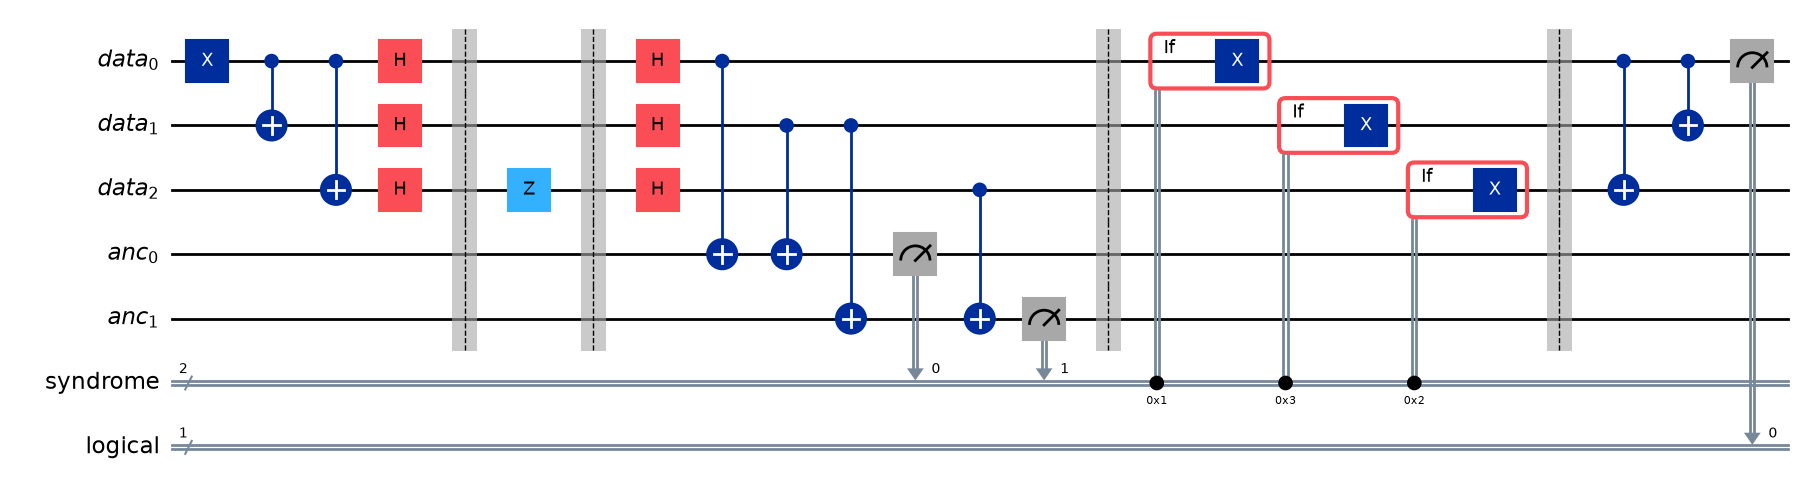

In [4]:
bit_flip_code(error_qubit=2, phase=True).draw('mpl', fold=-1)

In [5]:
for err in [None, 0, 1, 2]:
    counts = sim.run(transpile(bit_flip_code(error_qubit=err, phase=True), sim), shots=1000).result().get_counts()
    print(f"Z error on qubit {err}:  counts (logical syndrome) = {counts}")

Z error on qubit None:  counts (logical syndrome) = {'1 00': 1000}


Z error on qubit 0:  counts (logical syndrome) = {'1 01': 1000}
Z error on qubit 1:  counts (logical syndrome) = {'1 11': 1000}


Z error on qubit 2:  counts (logical syndrome) = {'1 10': 1000}


### Random noise: with vs without error correction
A noise model flips every data qubit with probability *p*. We compare the logical error rate of an **unprotected qubit**
with the **encoded + corrected** qubit.

p = 0.01:  without QEC error = 0.013   with QEC error = 0.000   (theory 3p^2-2p^3 = 0.000)


p = 0.05:  without QEC error = 0.054   with QEC error = 0.008   (theory 3p^2-2p^3 = 0.007)


p = 0.10:  without QEC error = 0.092   with QEC error = 0.029   (theory 3p^2-2p^3 = 0.028)


p = 0.20:  without QEC error = 0.193   with QEC error = 0.104   (theory 3p^2-2p^3 = 0.104)


p = 0.30:  without QEC error = 0.300   with QEC error = 0.203   (theory 3p^2-2p^3 = 0.216)


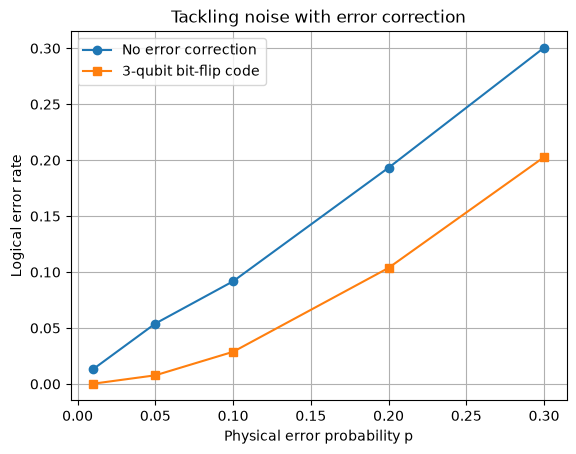

In [6]:
def unprotected():
    qc = QuantumCircuit(1, 1)
    qc.x(0)
    qc.id(0)          # noise acts here
    qc.measure(0, 0)
    return qc

shots = 4000
ps = [0.01, 0.05, 0.1, 0.2, 0.3]
raw_err, qec_err = [], []
for p in ps:
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(pauli_error([("X", p), ("I", 1 - p)]), ["id"])
    nsim = AerSimulator(noise_model=noise)

    c1 = nsim.run(transpile(unprotected(), nsim, optimization_level=0), shots=shots).result().get_counts()
    raw_err.append(c1.get("0", 0) / shots)

    c2 = nsim.run(transpile(bit_flip_code(noisy_id=True), nsim, optimization_level=0), shots=shots).result().get_counts()
    wrong = sum(v for k, v in c2.items() if k.split()[0] == "0")
    qec_err.append(wrong / shots)
    print(f"p = {p:.2f}:  without QEC error = {raw_err[-1]:.3f}   with QEC error = {qec_err[-1]:.3f}   (theory 3p^2-2p^3 = {3*p**2-2*p**3:.3f})")

plt.plot(ps, raw_err, "o-", label="No error correction")
plt.plot(ps, qec_err, "s-", label="3-qubit bit-flip code")
plt.xlabel("Physical error probability p"); plt.ylabel("Logical error rate")
plt.title("Tackling noise with error correction"); plt.legend(); plt.grid(True)
plt.show()

**Conclusion:** Encoding one logical qubit into three physical qubits, measuring the error syndrome with ancillas and
applying a conditional correction removes any single bit-flip (or, with Hadamards, phase-flip) error. Under random noise
the logical error rate falls from *p* to ≈ 3p², so error correction effectively tackles noise for small *p*.